<img src = "https://drive.google.com/uc?export=view&id=1lrzkRlmABf8ZwwCzsSvo0b2lW_IhZXkv" alt = "Encabezado MLDS" width = "100%">  </img>


# **Preparación de los datos**
---

Este notebook es una plantilla que le puede servir como guía para el tercer entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. ---**INGRESE SU RESPUESTA**---
2. ---**INGRESE SU RESPUESTA**---
3. ---**INGRESE SU RESPUESTA**---

In [1]:
import zipfile
import tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# --- Ubicación de los datos en el repositorio ---
DATA_DIR = Path(
    "../../data/raw/elecciones_2026/extracted/"
    "MMV_Presidente1V_2026/MMV_Presidente1V_2026"
)
assert DATA_DIR.is_dir(), f"No se encontró el directorio de datos: {DATA_DIR.resolve()}"

# Los ZIP internos (catálogos y novedades) se descomprimen en una carpeta temporal,
# para no modificar la carpeta de datos originales del repositorio.
EXTRA_DIR = Path(tempfile.gettempdir()) / "mmv_presidente_2026"
EXTRA_DIR.mkdir(parents=True, exist_ok=True)
for zip_interno in ["ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip", "Novedad20260603.zip"]:
    with zipfile.ZipFile(DATA_DIR / zip_interno) as z:
        z.extractall(EXTRA_DIR / Path(zip_interno).stem)

def buscar_archivo(patron, directorios=(DATA_DIR, EXTRA_DIR)):
    for d in directorios:
        resultados = list(Path(d).rglob(patron))
        if resultados:
            return resultados[0]
    raise FileNotFoundError(f"No se encontró '{patron}'")

ARCH_PRECONTEO  = buscar_archivo("PRE1v_MMV_9999_PRECONTEO.txt")
ARCH_ESCRUTINIO = buscar_archivo("_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv")
ARCH_NOVEDADES  = buscar_archivo("Novedad20260603.csv")
DIR_BASICOS     = buscar_archivo("HASH.txt").parent
PRECONTEO_PATH  = ARCH_PRECONTEO          # nombre que usa la sección de preconteo

# --- Preconteo (ancho fijo) ---
COLS_PRE   = ["dep", "mun", "zona", "puesto", "mesa", "jal", "comunicado",
              "circ", "partido", "candidato", "votos"]
ANCHOS_PRE = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]
precon = pd.read_fwf(ARCH_PRECONTEO, widths=ANCHOS_PRE, names=COLS_PRE,
                     dtype=str, encoding="latin-1")
precon["votos"] = precon["votos"].astype("int64")

# --- Escrutinio (separado por ;) ---
COLS_ESC = ["comunicado", "dep", "mun", "zona", "puesto", "mesa", "comuna",
            "corporacion", "circ", "partido", "candidato", "votos"]
escru = pd.read_csv(ARCH_ESCRUTINIO, sep=";", header=None, usecols=range(12),
                    names=COLS_ESC, dtype=str, encoding="latin-1")
escru["votos"] = escru["votos"].astype("int64")

# --- Novedades (UTF-8; repara las 45 líneas con comas en el nombre del puesto) ---
def leer_novedades(ruta):
    with open(ruta, encoding="utf-8") as f:
        encabezado = f.readline().rstrip("\r\n").split(",")
        n_campos, i_nombre = len(encabezado), encabezado.index("puestoNombre")
        n_cola = n_campos - i_nombre - 1
        filas = []
        for linea in f:
            partes = linea.rstrip("\r\n").split(",")
            if len(partes) > n_campos:
                partes = (partes[:i_nombre]
                          + [",".join(partes[i_nombre:len(partes) - n_cola])]
                          + partes[-n_cola:])
            filas.append(partes)
    return pd.DataFrame(filas, columns=encabezado)

noved = leer_novedades(ARCH_NOVEDADES)
COLS_NUM_NOV = ["potencial", "sufragantesSegunE11", "firmasJurados", "votosUrna",
                "votosIncinerados", "sufragantesE11SegunE14", "totalVotos"]
noved[COLS_NUM_NOV] = noved[COLS_NUM_NOV].apply(pd.to_numeric, errors="coerce")

# --- Catálogos (ancho fijo) ---
def leer_catalogo(prefijo, anchos, nombres):
    ruta = next(DIR_BASICOS.glob(f"{prefijo}_*.TXT"))
    df = pd.read_fwf(ruta, widths=anchos, names=nombres, dtype=str, encoding="latin-1")
    return df.apply(lambda s: s.str.strip())

divipol = leer_catalogo(
    "DIVIPOL", [2, 3, 2, 2, 12, 30, 40, 1, 8, 8, 6, 2, 30],
    ["dep", "mun", "zona", "puesto", "dep_nombre", "mun_nombre", "puesto_nombre",
     "indicador_puesto", "potencial_hombres", "potencial_mujeres", "n_mesas",
     "comuna", "comuna_nombre"])
for c in ["potencial_hombres", "potencial_mujeres", "n_mesas"]:
    divipol[c] = divipol[c].astype("int64")
candidatos = leer_catalogo(
    "CANDIDATOS", [3, 1, 2, 3, 2, 5, 3, 1, 50, 50, 15, 1, 2],
    ["corporacion", "circ", "dep", "mun", "comuna", "partido", "candidato",
     "preferente", "nombre", "apellido", "cedula", "genero", "sorteo"])

# --- Normalización de llaves ---
LLAVE_MESA = ["dep", "mun", "zona", "puesto", "mesa"]
for df in (precon, escru):
    df["zona"] = df["zona"].str.zfill(3)
    df["partido"] = df["partido"].str.zfill(5)
divipol["zona"] = divipol["zona"].str.zfill(3)
noved = noved.rename(columns={"departamentoCodigo": "dep", "municipioCodigo": "mun",
                              "zonaNombre": "zona", "puestoCodigo": "puesto",
                              "mesaNumero": "mesa"})
noved["zona"] = noved["zona"].str.zfill(3)
noved["mesa"] = noved["mesa"].str.zfill(6)

print(f"Preconteo: {len(precon):,} | Escrutinio: {len(escru):,} | "
      f"Novedades: {len(noved):,} | DIVIPOL: {len(divipol):,}")

Preconteo: 1,479,506 | Escrutinio: 1,952,320 | Novedades: 118,350 | DIVIPOL: 14,438


## **1. Limpieza de los Datos**
---

La elección de las técnicas de preprocesamiento puede diferir en cada conjunto de datos. Recuerde que es posible aplicar, según sea necesario (no necesariamente todas), las técnicas generales que se han explorado en el curso. La elección dependerá del tipo de datos con el que esté trabajando.

A lo largo de esta entrega, busque responder las siguientes preguntas:

- ¿Cuáles fueron los criterios utilizados para identificar y tratar valores atípicos, datos faltantes o cualquier otra anomalía en el conjunto de datos durante el proceso de limpieza?
- ¿Cómo se justificaría la necesidad de cada paso de preprocesamiento en términos de mejora de la calidad de los datos y preparación para el análisis subsiguiente?

A continuación encontrará los puntos a tratar a medida que va realizando la preparación de los datos. En cada punto defina el estado en que se encontraba el dataset, ademas de explicar y justificar las acciones y decisiones que se tomaron.

### **1.1. Valores faltantes**
---
Al encontrarnos con valores faltantes en el conjunto de datos, es crucial preguntarse:
* ¿Cómo afectan estos valores a la integridad y representatividad de la información?
* ¿Cómo se identificaron los valores faltantes en el conjunto de datos?
* ¿Cuáles fueron los criterios para decidir si rellenar con valores estimados o eliminar los valores faltantes? En caso que aplique, ¿qué método de relleno se utilizó y por qué se consideró apropiado?
* ¿Se realizó un análisis de la distribución de los valores faltantes en relación con las variables clave? Por ejemplo, si hay valores faltantes en una variable crítica, ¿cómo podría afectar la interpretación de los resultados?

#### Escrutinio

**¿Cómo se identificaron los valores faltantes en el conjunto de datos?**

In [2]:
print("Valores nulos por columna:")
print(escru.isnull().sum())

texto = escru.select_dtypes(exclude="number").columns
print("\nCeldas vacías o solo con espacios:", (escru[texto].apply(lambda s: s.str.strip()) == "").sum().sum())

filas_mesa = escru.groupby(LLAVE_MESA).size()
print("\nMesas:", len(filas_mesa), "| filas por mesa:", filas_mesa.value_counts().to_dict())
print("Filas esperadas (mesas x 16):", len(filas_mesa) * 16, "| filas reales:", len(escru))

Valores nulos por columna:
comunicado     0
dep            0
mun            0
zona           0
puesto         0
mesa           0
comuna         0
corporacion    0
circ           0
partido        0
candidato      0
votos          0
dtype: int64

Celdas vacías o solo con espacios: 0

Mesas: 122020 | filas por mesa: {16: 122020}
Filas esperadas (mesas x 16): 1952320 | filas reales: 1952320


Se revisaron tres formas en que un dato puede faltar:

1. **Valores nulos** (`isnull`): ninguna de las 12 columnas tiene nulos.
2. **Celdas vacías o con solo espacios**, que `isnull` no detecta porque se leen como texto: hay 0.
3. **Filas ausentes**: en un archivo en formato largo, un dato también falta si una mesa no tiene fila para alguna candidatura. Las 122 020 mesas tienen exactamente 16 filas, una por cada opción, y el total de filas (1 952 320) es igual a mesas × 16. El escrutinio trae la rejilla completa.

En conclusión, el estado inicial del escrutinio es **sin valores faltantes**. Esto lo diferencia del preconteo, al que le faltan filas. Cuando se comparen las dos fuentes, el escrutinio sirve de referencia completa.

**¿Se realizó un análisis de la distribución de los valores faltantes en relación con las variables clave?**

candidato
001      0.1
002     41.4
003     34.8
004      0.6
005     73.5
006     81.6
007     86.4
008     90.0
009    100.0
010     96.2
011      4.7
012     10.9
013    100.0
996     12.1
997     29.0
998     65.4


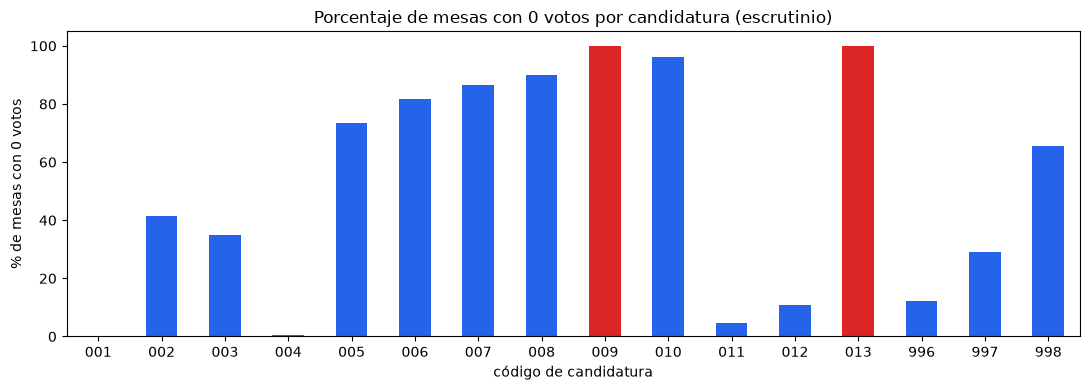

In [3]:
pct_ceros = escru.groupby("candidato")["votos"].apply(lambda s: (s == 0).mean() * 100).round(1)
print(pct_ceros.to_string())

fig, ax = plt.subplots(figsize=(11, 4))
colores = ["#DC2626" if c in ("009", "013") else "#2563EB" for c in pct_ceros.index]
pct_ceros.plot.bar(ax=ax, color=colores)
ax.set_xlabel("código de candidatura")
ax.set_ylabel("% de mesas con 0 votos")
ax.set_title("Porcentaje de mesas con 0 votos por candidatura (escrutinio)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

*Figura: Porcentaje de mesas con 0 votos por candidatura en el escrutinio; en rojo, los candidatos retirados (elaboración propia).*

Aunque no hay faltantes, se revisó si algún **cero** podía ser en realidad un dato faltante. Un 0 en `votos` es un valor registrado: la candidatura no recibió votos en esa mesa. La proporción de ceros depende de cada candidatura, desde 0,1 % (001) hasta 96,2 % (010), lo que refleja su votación y no una falla de registro.

La excepción son **009 y 013, con 0 votos en el 100 % de las mesas**. No es que falten sus datos: los dos candidatos se retiraron y en el escrutinio sus votos pasaron al código 998. Son columnas sin información, pero no se rellenan ni se reconstruyen. El traslado se descuenta al construir la variable objetivo, y la decisión sobre conservarlas o eliminarlas se toma en la selección de datos (1.6).

In [4]:
votos_mesa = escru.groupby(LLAVE_MESA)["votos"].sum().reset_index()
mesas_cero = votos_mesa[votos_mesa["votos"] == 0]
mesas_cero = mesas_cero.merge(noved[LLAVE_MESA + ["excluida"]], on=LLAVE_MESA, how="left")
mesas_cero["origen"] = np.where(mesas_cero["dep"] == "88", "consulado",
                       np.where(mesas_cero["excluida"] == "SI", "excluida en escrutinio", "otra"))

print("Mesas con 0 votos en total:", len(mesas_cero))
print(mesas_cero["origen"].value_counts())
print("Mesas excluidas en todo el archivo de novedades:", (noved["excluida"] == "SI").sum())

Mesas con 0 votos en total: 46
origen
excluida en escrutinio    37
consulado                  9
Name: count, dtype: int64
Mesas excluidas en todo el archivo de novedades: 37


También se revisaron las mesas **sin ningún voto**, porque una mesa vacía podría ser un acta que no llegó. Hay 46 y todas tienen explicación:

- **37 mesas excluidas en el escrutinio.** Son exactamente las 37 que el archivo de novedades marca con `excluida = SI`: la comisión anuló su votación. No son faltantes sino el resultado real del escrutinio, así que **se conservan**. Además, son mesas corregidas (en el preconteo sí tenían votos), por lo que eliminarlas quitaría casos positivos de la variable objetivo.
- **9 mesas de consulados** donde nadie votó.

**¿Cuáles fueron los criterios para decidir si rellenar con valores estimados o eliminar los valores faltantes?**

In [5]:
con_nov = votos_mesa[LLAVE_MESA].merge(noved[LLAVE_MESA], on=LLAVE_MESA, how="left", indicator=True)
print("Mesas del escrutinio sin registro en novedades:", (con_nov["_merge"] == "left_only").sum())
print(con_nov.loc[con_nov["_merge"] == "left_only", "dep"].value_counts())

escru_nac = escru[escru["dep"] != "88"].copy()
print("\nAntes:", len(escru), "filas |", escru.groupby(LLAVE_MESA).ngroups, "mesas")
print("Después:", len(escru_nac), "filas |", escru_nac.groupby(LLAVE_MESA).ngroups, "mesas")

Mesas del escrutinio sin registro en novedades: 3670
dep
88    3670
Name: count, dtype: int64

Antes: 1952320 filas | 122020 mesas
Después: 1893600 filas | 118350 mesas


**¿Cuáles fueron los criterios para decidir si rellenar con valores estimados o eliminar los valores faltantes?**

En el escrutinio no fue necesario rellenar ni eliminar registros, porque no hay valores faltantes. El criterio aplicado fue verificar si los valores que podían parecer faltantes lo eran en realidad:

- **Ceros por candidatura:** son valores reales (nadie votó por esa opción en la mesa) y se conservan tal como están.
- **Ceros de 009 y 013:** se deben al retiro de los candidatos, no a datos perdidos. No se rellenan. El traslado de sus votos se descuenta al construir la variable objetivo, y en la selección de datos (1.6) se decide si sus columnas se conservan.
- **Las 46 mesas sin votos:** corresponden a 37 mesas excluidas por la comisión y 9 mesas de consulados donde nadie votó. Son resultados reales, por lo que se conservan.

#### Faltantes al cruzar el escrutinio con las novedades

El escrutinio está completo por sí solo. Sin embargo, para construir el conjunto de modelado hay que unirlo con el archivo de novedades, que aporta las variables del formulario (E-11, E-14, votos en urna, firmas). Por eso se revisó si alguna mesa del escrutinio queda sin esa información al hacer el cruce.

In [6]:
votos_mesa = escru.groupby(LLAVE_MESA)["votos"].sum().reset_index()
cruce = votos_mesa[LLAVE_MESA].merge(noved[LLAVE_MESA], on=LLAVE_MESA, how="left", indicator=True)

print("Mesas del escrutinio:", len(cruce))
print("Mesas con registro en novedades:", (cruce["_merge"] == "both").sum())
print("Mesas sin registro en novedades:", (cruce["_merge"] == "left_only").sum())
print("\nDepartamento de las mesas sin novedades:")
print(cruce.loc[cruce["_merge"] == "left_only", "dep"].value_counts())

Mesas del escrutinio: 122020
Mesas con registro en novedades: 118350
Mesas sin registro en novedades: 3670

Departamento de las mesas sin novedades:
dep
88    3670
Name: count, dtype: int64


In [7]:
votos_mesa = escru.groupby(LLAVE_MESA)["votos"].sum().reset_index()
print("Escrutinio, todas las mesas:", votos_mesa["votos"].sum())
print("Escrutinio, solo consulados:", votos_mesa.loc[votos_mesa["dep"] == "88", "votos"].sum())
print("Escrutinio, sin consulados: ", votos_mesa.loc[votos_mesa["dep"] != "88", "votos"].sum())
print("Novedades (totalVotos):     ", noved["totalVotos"].sum())

m = votos_mesa.merge(noved[LLAVE_MESA + ["totalVotos"]], on=LLAVE_MESA)
print("% de mesas donde coinciden:", (m["votos"] == m["totalVotos"]).mean() * 100)

Escrutinio, todas las mesas: 23990635
Escrutinio, solo consulados: 591234
Escrutinio, sin consulados:  23399401
Novedades (totalVotos):      23399401
% de mesas donde coinciden: 100.0


Al cruzar las dos fuentes, **3 670 mesas del escrutinio quedan sin datos del formulario**, y todas son del departamento 88 (consulados). El archivo de novedades solo incluye mesas nacionales. Las otras 118 350 mesas cruzan sin problema.

**Decisión: eliminar las mesas de consulados en lugar de rellenarlas.** Las razones son tres:

1. Las variables que les faltan son las más importantes para el modelo, en especial la diferencia entre el preconteo y el E-11. Un valor estimado inventaría justo la señal que el modelo debe aprender.
2. Las variables faltan para todo el grupo de consulados, no al azar dentro de él, así que no hay información de mesas parecidas para estimarlas.
3. Los consulados siguen un proceso de escrutinio distinto al nacional.

**Efecto en la representatividad:** el modelo queda limitado al escrutinio nacional, que corresponde al 97 % de las mesas (118 350 de 122 020). Sus conclusiones no deben extenderse al voto en el exterior.

El escrutinio pasa de 1 952 320 filas (122 020 mesas) a **1 893 600 filas (118 350 mesas nacionales)**. Las 9 mesas de consulados sin votos salen junto con ellas. Desde aquí, las secciones siguientes trabajan con `escru_nac`.

**¿Se realizó un análisis de la distribución de los valores faltantes en relación con las variables clave?** 

 El E-11 es la variable más importante del modelo, porque la diferencia entre el preconteo y el E-11 es la principal señal de que una mesa será corregida. Si se conservaran los consulados con el E-11 vacío o estimado, el modelo podría interpretar como discrepancia algo que en realidad es un dato inventado o ausente. Esto inflaría o distorsionaría la relación entre esa diferencia y la corrección. Al excluirlos, todas las mesas del modelo tienen el E-11 real y la relación se interpreta sin ese sesgo.

**¿Cómo afectan estos valores a la integridad y representatividad de la información?**

In [8]:
mesas_total = escru.groupby(LLAVE_MESA).ngroups
mesas_nac = escru_nac.groupby(LLAVE_MESA).ngroups
votos_total = escru["votos"].sum()
votos_nac = escru_nac["votos"].sum()

print(f"Mesas:  {mesas_nac} de {mesas_total} ({mesas_nac / mesas_total * 100:.1f} %)")
print(f"Votos:  {votos_nac} de {votos_total} ({votos_nac / votos_total * 100:.1f} %)")
print("Departamentos que quedan:", escru_nac["dep"].nunique(), "de", escru["dep"].nunique())

Mesas:  118350 de 122020 (97.0 %)
Votos:  23399401 de 23990635 (97.5 %)
Departamentos que quedan: 33 de 34


**Integridad.** El escrutinio no tiene nulos ni celdas vacías, cada mesa tiene sus 16 filas y los ceros (incluidos los de los candidatos retirados y las 46 mesas sin votos) son resultados reales que se conservan. Como no se rellenó ningún valor, los votos de cada mesa son exactamente los que reporta la Registraduría.

Los faltantes aparecen solo **al unir** el escrutinio con las novedades. Las 3 670 mesas de consulados no tienen registro en el archivo de novedades, por lo que en la tabla unida quedarían con las variables del formulario vacías. Si se conservaran, la integridad del conjunto de modelado sí se vería afectada, porque esas mesas no tendrían el E-11, que es la variable más importante. Al excluirlas, todas las mesas que quedan tienen sus datos completos y reales en las dos fuentes.

### **1.2. Valores duplicados**
----
Ante la presencia de valores duplicados, es esencial reflexionar sobre su impacto en los resultados.

* ¿Cómo se identificaron y manejaron los valores duplicados en el conjunto de datos?
* ¿Hubo alguna consideración especial al tratar duplicados en función de ciertas variables?
* ¿Pueden estos duplicados sesgar el análisis, y en qué medida?
* ¿Se justifica la eliminación de duplicados para mantener la coherencia y singularidad de los datos?
* ¿Cómo se aseguró de que la eliminación de duplicados no afectara negativamente la representación del conjunto de datos?

La identificación y eliminación de duplicados busca asegurar que cada registro aporte información única y valiosa.

#### Escrutinio

**¿Cómo se identificaron y manejaron los valores duplicados en el conjunto de datos?**

In [9]:
print("Filas completas duplicadas:", escru_nac.duplicated().sum())
print("Mesa + candidatura duplicadas:", escru_nac.duplicated(subset=LLAVE_MESA + ["candidato"]).sum())

Filas completas duplicadas: 0
Mesa + candidatura duplicadas: 0


Se buscaron duplicados en dos niveles:

1. **Filas completas repetidas** (`duplicated()`): dos filas idénticas en todas sus columnas. Hay 0.
2. **Duplicados por llave**: la misma mesa con la misma candidatura más de una vez, aunque los votos fueran distintos. Este es el duplicado más peligroso, porque significaría que una mesa reportó dos resultados para la misma opción. Hay 0.

Como no se encontraron duplicados, no fue necesario eliminar registros.

**¿Hubo alguna consideración especial al tratar duplicados en función de ciertas variables?**

In [10]:
print("Números de mesa distintos:", escru_nac["mesa"].nunique())
print("Mesas reales (llave completa):", escru_nac.groupby(LLAVE_MESA).ngroups)

print("\n'Duplicados' si se usa solo mesa + candidatura:",
      escru_nac.duplicated(subset=["mesa", "candidato"]).sum())
print("'Duplicados' si se usa puesto + mesa + candidatura:",
      escru_nac.duplicated(subset=["puesto", "mesa", "candidato"]).sum())

Números de mesa distintos: 228
Mesas reales (llave completa): 118350

'Duplicados' si se usa solo mesa + candidatura: 1889952
'Duplicados' si se usa puesto + mesa + candidatura: 1827184


Sí. La consideración principal fue **usar la llave completa de la mesa**. El número de mesa solo identifica una mesa dentro de su puesto: la "mesa 1" existe en casi todos los puestos del país. Por eso hay solo 228 números de mesa distintos, pero 118 350 mesas reales.

Si los duplicados se buscaran solo con `mesa` + candidatura, aparecerían 1 889 952 "duplicados" falsos. Incluso agregando el puesto, aparecerían 1 827 184, porque los códigos de puesto también se repiten entre municipios. Eliminar esos registros habría borrado casi todo el conjunto. Por eso la verificación se hizo con la llave completa: departamento, municipio, zona, puesto y mesa.

**¿Pueden estos duplicados sesgar el análisis, y en qué medida?**

In [11]:
esc_mesa = escru_nac.pivot_table(index=LLAVE_MESA, columns="candidato", values="votos",
                                 aggfunc="sum").reset_index()
CANDS = [c for c in esc_mesa.columns if c not in LLAVE_MESA]
esc_mesa["total"] = esc_mesa[CANDS].sum(axis=1)
esc_mesa["opciones_con_votos"] = (esc_mesa[CANDS] > 0).sum(axis=1)

PUESTO = ["dep", "mun", "zona", "puesto"]
igual_puesto = esc_mesa.duplicated(subset=PUESTO + CANDS, keep=False) & (esc_mesa["total"] > 0)
igual_pais = esc_mesa.duplicated(subset=CANDS, keep=False) & (esc_mesa["total"] > 0)
print("Mesas con resultado idéntico a otra del MISMO puesto:", igual_puesto.sum())
print("Mesas con resultado idéntico a otra de cualquier parte del país:", igual_pais.sum())

iguales = esc_mesa[igual_pais]
print(f"\nDe esas {len(iguales)} mesas:")
print(f"- mediana de votos: {iguales['total'].median():.0f} (todas las mesas: {esc_mesa['total'].median():.0f})")
print(f"- con 30 votos o menos: {(iguales['total'] <= 30).mean() * 100:.1f} %")
print(f"- con votos en solo 1 o 2 opciones: {(iguales['opciones_con_votos'] <= 2).mean() * 100:.1f} %")
print(f"- en zona rural (099): {(iguales['zona'] == '099').mean() * 100:.1f} % "
      f"(todas las mesas: {(esc_mesa['zona'] == '099').mean() * 100:.1f} %)")

Mesas con resultado idéntico a otra del MISMO puesto: 0
Mesas con resultado idéntico a otra de cualquier parte del país: 551

De esas 551 mesas:
- mediana de votos: 13 (todas las mesas: 206)
- con 30 votos o menos: 80.9 %
- con votos en solo 1 o 2 opciones: 60.3 %
- en zona rural (099): 67.5 % (todas las mesas: 16.4 %)


Si existieran, los duplicados sí sesgarían el análisis: una mesa repetida contaría doble sus votos y, en el modelo, tendría el doble de peso en el entrenamiento. Por eso, además de las filas, se revisó un tipo de duplicado más sutil: **actas copiadas**, es decir, dos mesas con exactamente los mismos votos en las 16 opciones. Esto podría indicar que un resultado se transcribió dos veces.

- **Dentro del mismo puesto no hay ninguna mesa con resultado idéntico a otra.** Es el caso donde una copia sería más probable, porque las actas se diligencian en el mismo lugar.
- **En todo el país hay 551 mesas** (0,5 %) cuyo resultado coincide con el de otra mesa de otro puesto. Estas coincidencias tienen una explicación por azar: son mesas muy pequeñas (mediana de 13 votos frente a 206 en general; el 80,9 % tiene 30 votos o menos), con votos concentrados en 1 o 2 opciones (60,3 %) y ubicadas sobre todo en zona rural (67,5 % frente a 16,4 % en general). Con tan pocos votos y tan concentrados, es esperable que dos mesas lejanas den el mismo resultado.

Por eso estas 551 mesas no se consideran duplicados y **se conservan**: son mesas distintas, en lugares distintos, con resultados que coinciden por azar.

**¿Se justifica la eliminación de duplicados? ¿Cómo se aseguró de que no afectara negativamente la representación del conjunto de datos?**

In [12]:
print("Antes de la revisión: ", len(escru_nac), "filas |", escru_nac.groupby(LLAVE_MESA).ngroups, "mesas")
escru_nac = escru_nac.drop_duplicates()
print("Después de la revisión:", len(escru_nac), "filas |", escru_nac.groupby(LLAVE_MESA).ngroups, "mesas")
print("Votos totales:", escru_nac["votos"].sum())

Antes de la revisión:  1893600 filas | 118350 mesas
Después de la revisión: 1893600 filas | 118350 mesas
Votos totales: 23399401


No se justificó eliminar registros, porque no hay duplicados reales. Igualmente se aplicó `drop_duplicates()` como paso de control y se comparó el conjunto antes y después: conserva las mismas 1 893 600 filas, las mismas 118 350 mesas y los mismos 23 399 401 votos. Así se confirma que la revisión no alteró la representación del conjunto.

Se descartaron dos acciones que sí la habrían afectado: buscar duplicados con una llave incompleta, que habría borrado casi todo el conjunto, y eliminar las 551 mesas con resultados coincidentes, que habría quitado sobre todo mesas rurales pequeñas y sesgado el conjunto hacia las mesas urbanas.

Este control se repetirá al unir el escrutinio con el preconteo y las novedades, verificando que cada mesa siga apareciendo una sola vez.

In [13]:
print("Mesas en el escrutinio:", len(esc_mesa), "| repetidas:", esc_mesa.duplicated(subset=LLAVE_MESA).sum())
print("Mesas en novedades:", len(noved), "| repetidas:", noved.duplicated(subset=LLAVE_MESA).sum())

unida = esc_mesa.merge(noved, on=LLAVE_MESA, how="outer", validate="1:1", indicator=True)
print("\nFilas de la tabla unida:", len(unida))
print(unida["_merge"].value_counts())
print("Mesas repetidas en la tabla unida:", unida.duplicated(subset=LLAVE_MESA).sum())

Mesas en el escrutinio: 118350 | repetidas: 0
Mesas en novedades: 118350 | repetidas: 0

Filas de la tabla unida: 118350
_merge
both          118350
left_only          0
right_only         0
Name: count, dtype: int64
Mesas repetidas en la tabla unida: 0


**Duplicados al unir el escrutinio con las novedades.** Los duplicados también pueden aparecer al unir fuentes: si una mesa estuviera dos veces en novedades, la unión la repetiría y sus votos contarían doble. Para evitarlo, se verificó que cada mesa aparezca una sola vez en cada fuente y se hizo la unión con `validate="1:1"`, que detiene la ejecución con un error si alguna mesa se empareja con más de una fila.

La unión resultó uno a uno: las 118 350 mesas del escrutinio encuentran exactamente una pareja en novedades (`both`), no sobra ninguna de ningún lado y la tabla unida tiene 118 350 filas, sin mesas repetidas.

### **1.3. Valores atípicos**
---
Al abordar valores atípicos, es relevante cuestionarse sobre la naturaleza de estos puntos extremos.
* ¿Son errores de medición o representan información válida pero excepcional?
* ¿Qué criterios o técnicas se utilizaron para identificar los valores atípicos?
* ¿Se aplicaron métodos estadísticos o visuales para detectar los valores atípicos?
* ¿Cuál fue la decisión final sobre cómo tratar los valores atípicos y por qué?

La elección entre eliminar o transformar estos valores debe basarse en su influencia en la distribución y la interpretación de los resultados, asegurando que el análisis refleje de manera precisa la realidad del conjunto de datos.

---**INGRESE SU RESPUESTA**---

In [ ]:
# ---INGRESE SU CÓDIGO---

### **1.4. Datos Inconsistentes**
---
Frente a inconsistencias en los datos, es importante analizar cómo estas discrepancias podrían afectar la comparabilidad y comprensión de la información.

* ¿Cómo se identificaron las inconsistencias en los datos?
* ¿Las inconsistencias son lo suficientemente significativas como para justificar una estandarización?
* ¿Cómo se pueden homogeneizar unidades y formatos para garantizar coherencia en el análisis?
* ¿Qué estrategias se implementaron para abordar las inconsistencias y asegurar la coherencia?
* ¿Se establecieron reglas de validación específicas para garantizar la consistencia?

---**INGRESE SU RESPUESTA**---

In [ ]:
# ---INGRESE SU CÓDIGO---

### **1.5. Datos corruptos**
---
En la detección de datos corruptos, pregunte si hay posibles errores de entrada o problemas de transferencia que podrían haber afectado la integridad de los datos.
* ¿Cómo se determinó la presencia de datos corruptos en el conjunto de datos?
* ¿Qué medidas se tomaron para corregir o eliminar los datos corruptos?
* ¿Hubo casos en los que la corrupción de datos no pudo ser manejada y cómo se justificó esa decisión?

---**INGRESE SU RESPUESTA**---

In [ ]:
# ---INGRESE SU CÓDIGO---

### **1.6. Selección de datos**
---
En la selección de datos, reflexione sobre las variables que son realmente relevantes para sus objetivos de análisis.
* ¿Qué criterios se utilizaron para seleccionar los datos relevantes para el análisis?
* ¿Se aplicaron técnicas de muestreo o filtrado para reducir el tamaño del conjunto de datos?
* ¿Cómo se justificó la inclusión o exclusión de ciertas variables en la selección de datos?

---**INGRESE SU RESPUESTA**---

In [ ]:
# ---INGRESE SU CÓDIGO---

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*